Q1)

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = sns.load_dataset('titanic')
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [17]:
female = df[df['sex'] == 'female']['survived'].dropna()

n=len(female)
s = female.sum()
nonsurv = n-s
print("total female passenger : ",n)
print("total female survived : ",s)
print("total female not survived : ",nonsurv)


total female passenger :  314
total female survived :  233
total female not survived :  81


In [14]:
theta_values = np.arange(0.1,1.0,0.1)
print(theta_values)

[0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]


In [15]:
prior = np.ones(len(theta_values)) / len(theta_values)
print(prior)

[0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]


In [18]:
log_likelihood = (
    s * np.log(theta_values) +
    nonsurv * np.log(1 - theta_values)
)
likelihood = np.exp(log_likelihood)
print(likelihood)

[1.96627050e-237 1.95109284e-171 4.18980288e-135 2.04281605e-111
 2.99627287e-095 1.19151808e-084 3.58645145e-079 6.35911411e-080
 2.18024199e-092]


In [19]:
unnormalized_posterior = prior * likelihood
posterior = unnormalized_posterior / unnormalized_posterior.sum()
print(posterior)


[4.65678821e-159 4.62084242e-093 9.92285883e-057 4.83807373e-033
 7.09617935e-017 2.82191455e-006 8.49392022e-001 1.50605156e-001
 5.16354447e-014]


In [20]:
results = pd.DataFrame({
    'theta_value': theta_values,
    'prior': prior,
    'likelihood': likelihood,
    'unnormalized_posterior': unnormalized_posterior,
    'posterior': posterior
})
print(results)

   theta_value     prior     likelihood  unnormalized_posterior      posterior
0          0.1  0.111111  1.966271e-237           2.184745e-238  4.656788e-159
1          0.2  0.111111  1.951093e-171           2.167881e-172   4.620842e-93
2          0.3  0.111111  4.189803e-135           4.655337e-136   9.922859e-57
3          0.4  0.111111  2.042816e-111           2.269796e-112   4.838074e-33
4          0.5  0.111111   2.996273e-95            3.329192e-96   7.096179e-17
5          0.6  0.111111   1.191518e-84            1.323909e-85   2.821915e-06
6          0.7  0.111111   3.586451e-79            3.984946e-80   8.493920e-01
7          0.8  0.111111   6.359114e-80            7.065682e-81   1.506052e-01
8          0.9  0.111111   2.180242e-92            2.422491e-93   5.163544e-14


THE BEST VALUE OF THETA IS (0.7) AS THE POSTERIOR VALUE OF THETA (0.7) IS MAXIMUM

In [22]:
posterior_mean = np.sum(theta_values * posterior)
print("Posterior mean: ",posterior_mean)

Posterior mean:  0.7150602333958676


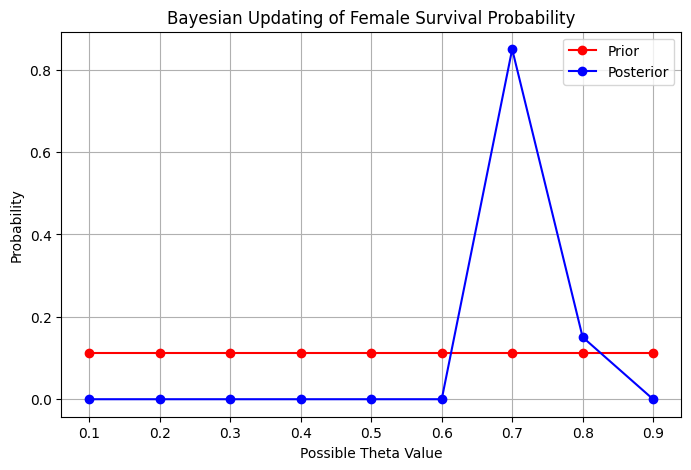

In [28]:
plt.figure(figsize=(8,5))

plt.plot(
    theta_values,
    prior,
    marker='o',
    linestyle='-',
    color='r',
    label='Prior'
)
plt.plot(
    theta_values,
    posterior,
    marker='o',
    linestyle='-',
    color='b',
    label='Posterior'
)
plt.xlabel('Possible Theta Value')
plt.ylabel('Probability')
plt.title('Bayesian Updating of Female Survival Probability')
plt.legend()
plt.grid(True)
plt.show()